In [1]:

# Import libraries for hierarchical clustering
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

# Load the processed customer features and metadata
X_processed = pd.read_csv("../data/processed/customer_features.csv")
metadata = pd.read_csv("../data/processed/customer_metadata.csv")

print("Feature matrix shape:", X_processed.shape)
print("Metadata shape:", metadata.shape)

X_processed.head()


Feature matrix shape: (7043, 45)
Metadata shape: (7043, 2)


,num__SeniorCitizen,num__tenure,num__MonthlyCharges,num__TotalCharges,cat__gender_Female,cat__gender_Male,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,cat__Dependents_Yes,...,cat__StreamingMovies_Yes,cat__Contract_Month-to-month,cat__Contract_One year,cat__Contract_Two year,cat__PaperlessBilling_No,cat__PaperlessBilling_Yes,cat__PaymentMethod_Bank transfer (automatic),cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check
0,-0.439916,-1.277445,-1.160323,-0.992611,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,-0.439916,0.066327,-0.259629,-0.172165,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,-0.439916,-1.236724,-0.362660,-0.958066,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,-0.439916,0.514251,-0.746535,-0.193672,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,-0.439916,-1.236724,0.197365,-0.938874,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [2]:

# Select a reproducible sample for dendrogram visualization
X_sample = X_processed.sample(
    n=500,
    random_state=42
)

# Calculate the hierarchical cluster-merging structure
linkage_matrix = linkage(
    X_sample,
    method="ward",
    metric="euclidean"
)

print("Sample size:", X_sample.shape[0])
print("Linkage matrix shape:", linkage_matrix.shape)


Sample size: 500
Linkage matrix shape: (499, 4)


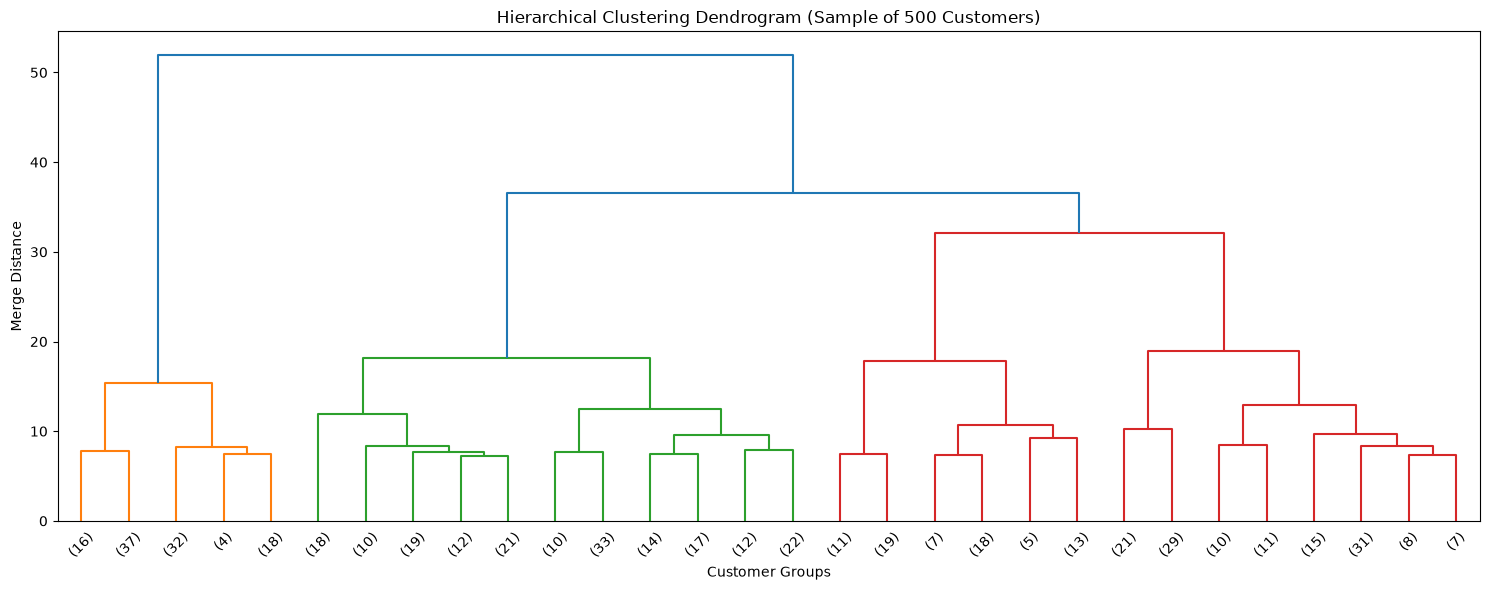

In [3]:

# Plot the hierarchical clustering dendrogram
plt.figure(figsize=(15, 6))

dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

plt.title("Hierarchical Clustering Dendrogram (Sample of 500 Customers)")
plt.xlabel("Customer Groups")
plt.ylabel("Merge Distance")
plt.tight_layout()
plt.show()


In [4]:

# Fit hierarchical clustering with 3 clusters
hierarchical_model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

hierarchical_labels = hierarchical_model.fit_predict(X_processed)

# Store the cluster assignments alongside the customer metadata
hierarchical_results = metadata.copy()
hierarchical_results["Cluster"] = hierarchical_labels

# Display the number of customers in each cluster
print("Hierarchical cluster sizes:")
print(
    hierarchical_results["Cluster"]
    .value_counts()
    .sort_index()
)

# Evaluate cluster separation using a reproducible sample
hierarchical_silhouette = silhouette_score(
    X_processed,
    hierarchical_labels,
    sample_size=2000,
    random_state=42
)

print(
    f"\nSampled Silhouette Score: "
    f"{hierarchical_silhouette:.4f}"
)


Hierarchical cluster sizes:
Cluster
0    3462
1    1526
2    2055
Name: count, dtype: int64

Sampled Silhouette Score: 0.1996


In [5]:

# Load the original data for interpreting the clusters
hierarchical_profile = pd.read_csv(
    "../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

# Attach the hierarchical cluster assignments
hierarchical_profile["Cluster"] = hierarchical_labels

# Convert TotalCharges to numeric
hierarchical_profile["TotalCharges"] = pd.to_numeric(
    hierarchical_profile["TotalCharges"],
    errors="coerce"
).fillna(0)

# Summarize numerical characteristics
print("Average customer characteristics by cluster:")
print(
    hierarchical_profile.groupby("Cluster")[
        ["tenure", "MonthlyCharges", "TotalCharges"]
    ].mean().round(2)
)

# Calculate observed churn rate
print("\nObserved churn rate by cluster (%):")
print(
    hierarchical_profile.groupby("Cluster")["Churn"]
    .apply(lambda values: (values == "Yes").mean() * 100)
    .round(2)
)

# Display churn counts
print("\nChurn counts by cluster:")
print(
    pd.crosstab(
        hierarchical_profile["Cluster"],
        hierarchical_profile["Churn"]
    )
)


Average customer characteristics by cluster:
         tenure  MonthlyCharges  TotalCharges
Cluster                                      
0         20.52           71.35       1566.58
1         30.55           21.08        662.60
2         53.70           86.11       4682.01

Observed churn rate by cluster (%):
Cluster
0    42.61
1     7.40
2    13.67
Name: Churn, dtype: float64

Churn counts by cluster:
Churn      No   Yes
Cluster            
0        1987  1475
1        1413   113
2        1774   281


## Hierarchical Clustering — Summary

### Objective
Applied agglomerative hierarchical clustering to segment telecom customers and compared the resulting segments with K-Means.

### Methodology
- Used the same 45 processed features as the K-Means experiment.
- Generated a Ward-linkage dendrogram using a reproducible sample of 500 customers.
- Fitted agglomerative clustering with Ward linkage and three clusters on all 7,043 customers.
- Evaluated separation using a sampled silhouette score.
- Profiled the clusters using numerical characteristics and observed churn rates.

### Results

| Cluster | Customers | Average Tenure (months) | Average Monthly Charges | Observed Churn Rate |
|---|---:|---:|---:|---:|
| 0 | 3,462 | 20.52 | 71.35 | 42.61% |
| 1 | 1,526 | 30.55 | 21.08 | 7.40% |
| 2 | 2,055 | 53.70 | 86.11 | 13.67% |

### Evaluation
The sampled silhouette score was 0.1996, lower than the K-Means score of 0.2383 under the current evaluation setup.

### Business Interpretation
- **Cluster 0:** Shorter-tenure, higher-monthly-charge customers with high observed churn.
- **Cluster 1:** Lower-cost customers with low observed churn.
- **Cluster 2:** Longer-tenure, higher-spending customers with below-average observed churn.

Cluster 0 may be a useful target for further churn and retention analysis. These patterns are associations and do not establish causal relationships.

### Limitations
- The dendrogram was generated from a sample rather than the entire dataset.
- The three-cluster configuration was selected to enable comparison with K-Means.
- A lower silhouette score suggests relatively weak geometric separation.
- Cluster labels are arbitrary and cannot be matched directly to K-Means labels by number.

### Conclusion
Hierarchical clustering produced three interpretable customer segments with different observed churn rates. Its results provide a useful comparison baseline for the DBSCAN experiment.